In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
/kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
/kaggle/input/competitions/nyc-taxi-trip-duration/sample_submission.zip


In [2]:
#!pip install pyspark

In [3]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.2


In [4]:
from pyspark.sql import SparkSession
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, isnan, lit, to_timestamp
from pyspark.sql.types import DoubleType, IntegerType

In [5]:
spark = SparkSession.builder \
    .appName("NYC Taxi Big Data Analysis") \
    .getOrCreate()
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/08 19:02:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [6]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
  inflating: /kaggle/working/train.csv  


In [7]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
  inflating: /kaggle/working/test.csv  


In [8]:
!ls /kaggle/working/

__notebook__.ipynb  test.csv  train.csv


In [9]:
df_train=spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/train.csv")

In [10]:
df_test =spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/test.csv")

In [11]:
df_train.printSchema()

root
 |-- id: string (nullable = true)
 |-- vendor_id: integer (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- trip_duration: integer (nullable = true)



In [12]:
df_test.show(truncate=False, vertical=True,n=2)

-RECORD 0---------------------------------
 id                 | id3004672           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-30 23:59:58 
 passenger_count    | 1                   
 pickup_longitude   | -73.98812866210938  
 pickup_latitude    | 40.73202896118164   
 dropoff_longitude  | -73.99017333984375  
 dropoff_latitude   | 40.75667953491211   
 store_and_fwd_flag | N                   
-RECORD 1---------------------------------
 id                 | id3505355           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-30 23:59:53 
 passenger_count    | 1                   
 pickup_longitude   | -73.96420288085938  
 pickup_latitude    | 40.67999267578125   
 dropoff_longitude  | -73.95980834960938  
 dropoff_latitude   | 40.65540313720703   
 store_and_fwd_flag | N                   
only showing top 2 rows


In [13]:
df_train.show(truncate=False, vertical=True,n=6)

-RECORD 0---------------------------------
 id                 | id2875421           
 vendor_id          | 2                   
 pickup_datetime    | 2016-03-14 17:24:55 
 dropoff_datetime   | 2016-03-14 17:32:30 
 passenger_count    | 1                   
 pickup_longitude   | -73.9821548461914   
 pickup_latitude    | 40.76793670654297   
 dropoff_longitude  | -73.96463012695312  
 dropoff_latitude   | 40.765602111816406  
 store_and_fwd_flag | N                   
 trip_duration      | 455                 
-RECORD 1---------------------------------
 id                 | id2377394           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-12 00:43:35 
 dropoff_datetime   | 2016-06-12 00:54:38 
 passenger_count    | 1                   
 pickup_longitude   | -73.98041534423828  
 pickup_latitude    | 40.738563537597656  
 dropoff_longitude  | -73.99948120117188  
 dropoff_latitude   | 40.73115158081055   
 store_and_fwd_flag | N                   
 trip_durat

In [14]:
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, FloatType

def check_nulls(df):
    exprs = []
    for field in df.schema.fields:
        c = field.name
        # isnan is only valid for DoubleType / FloatType
        if isinstance(field.dataType, (DoubleType, FloatType)):
            exprs.append(
                F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c)
            )
        else:
            exprs.append(
                F.count(F.when(F.col(c).isNull(), c)).alias(c)
            )
    return df.select(*exprs)

check_nulls(df_train).show(truncate=False,vertical=True)
check_nulls(df_test).show(truncate=False,vertical=True)

-RECORD 0-----------------
 id                 | 0   
 vendor_id          | 0   
 pickup_datetime    | 0   
 dropoff_datetime   | 0   
 passenger_count    | 0   
 pickup_longitude   | 0   
 pickup_latitude    | 0   
 dropoff_longitude  | 0   
 dropoff_latitude   | 0   
 store_and_fwd_flag | 0   
 trip_duration      | 0   



-RECORD 0-----------------
 id                 | 0   
 vendor_id          | 0   
 pickup_datetime    | 0   
 passenger_count    | 0   
 pickup_longitude   | 0   
 pickup_latitude    | 0   
 dropoff_longitude  | 0   
 dropoff_latitude   | 0   
 store_and_fwd_flag | 0   



In [15]:
from pyspark.sql.functions import log1p
from pyspark.sql import functions as F

# Summary statistics
df_train.select(
    F.min("trip_duration").alias("min_duration"),
    F.max("trip_duration").alias("max_duration"),
    F.mean("trip_duration").alias("mean_duration"),
    F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
    F.expr("percentile_approx(trip_duration, 0.99)").alias("p99_duration")
).show(truncate=False)

# Flag outliers using IQR method in Spark
bounds = df_train.select(
    F.expr("percentile_approx(trip_duration, 0.25)").alias("q1"),
    F.expr("percentile_approx(trip_duration, 0.75)").alias("q3")
).collect()[0]
q1, q3 = bounds.q1, bounds.q3
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

print(f"IQR bounds: [{lower_bound}, {upper_bound}]")

# Add outlier flag and log-transformed target
df_train = df_train.withColumn("log_trip_duration", log1p("trip_duration"))
df_train = df_train.withColumn(
    "duration_outlier",
    when((col("trip_duration") < lower_bound) | (col("trip_duration") > upper_bound), 1).otherwise(0)
)


+------------+------------+-----------------+---------------+------------+
|min_duration|max_duration|mean_duration    |median_duration|p99_duration|
+------------+------------+-----------------+---------------+------------+
|1           |3526282     |959.4922729603659|662            |3438        |
+------------+------------+-----------------+---------------+------------+



IQR bounds: [0, 2092.0]


# Optional: hard clip to reasonable range (e.g., 1% - 99%) and remove zero-duration trips


In [16]:
percs = df_train.select(
    F.expr("percentile_approx(trip_duration, 0.01)").alias("p01"),
    F.expr("percentile_approx(trip_duration, 0.99)").alias("p99")
).collect()[0]

df_train_clean = df_train.filter(
    (col("trip_duration") > 0) &
    (col("trip_duration") >= percs.p01) &
    (col("trip_duration") <= percs.p99)
)

In [17]:
from pyspark.sql.functions import (
    hour, dayofweek, month, year, 
    when, to_timestamp, col
)

# Ensure datetime format
df_train = df_train.withColumn("pickup_datetime", to_timestamp("pickup_datetime"))
df_test = df_test.withColumn("pickup_datetime", to_timestamp("pickup_datetime"))

# Train has dropoff_datetime; test does not
df_train = df_train.withColumn("dropoff_datetime", to_timestamp("dropoff_datetime"))

def add_datetime_features(df):
    df = df.withColumn("pickup_hour", hour("pickup_datetime"))
    df = df.withColumn("pickup_dayofweek", dayofweek("pickup_datetime"))  # 1=Sun, 7=Sat
    df = df.withColumn("pickup_month", month("pickup_datetime"))
    df = df.withColumn("pickup_year", year("pickup_datetime"))
    
    # Weekend flag (Saturday=7, Sunday=1)
    df = df.withColumn("is_weekend", when(col("pickup_dayofweek").isin([1, 7]), 1).otherwise(0))
    
    # Rush hour flags (morning 7-9, evening 17-19)
    df = df.withColumn(
        "is_rush_hour",
        when(
            ((col("pickup_hour") >= 7) & (col("pickup_hour") <= 9)) |
            ((col("pickup_hour") >= 17) & (col("pickup_hour") <= 19)), 
            1
        ).otherwise(0)
    )
    return df

df_train = add_datetime_features(df_train)
df_test = add_datetime_features(df_test)

# Sanity check: compute duration from timestamps on train
df_train = df_train.withColumn(
    "duration_from_delta",
    col("dropoff_datetime").cast("long") - col("pickup_datetime").cast("long")
)

# Check how many rows have mismatched durations
mismatch_count = df_train.filter(
    F.abs(col("duration_from_delta") - col("trip_duration")) > 60
).count()
print(f"Timestamp-derived mismatches (>60s): {mismatch_count}")

Timestamp-derived mismatches (>60s): 0


In [18]:
before = df_train.count()

#df_train_clean = filter_nyc_bounds(df_train)

after = df_train_clean.count()

print("Before:", before)
print("After:", after)
print("Removed:", before - after)

Before: 1458644
After: 1429501
Removed: 29143


In [19]:
from pyspark.sql.functions import radians, sin, cos, atan2, sqrt, lit

# NYC approximate bounds
MIN_LON, MAX_LON = -74.3, -73.7
MIN_LAT, MAX_LAT = 40.4, 40.9

def filter_nyc_bounds(df):
    return df.filter(
        (col("pickup_longitude").between(MIN_LON, MAX_LON)) &
        (col("pickup_latitude").between(MIN_LAT, MAX_LAT)) &
        (col("dropoff_longitude").between(MIN_LON, MAX_LON)) &
        (col("dropoff_latitude").between(MIN_LAT, MAX_LAT))
    )

df_train = filter_nyc_bounds(df_train)
df_test = filter_nyc_bounds(df_test)

# Remove identical pickup/dropoff
df_train = df_train.withColumn(
    "same_pickup_dropoff",
    when(
        (col("pickup_longitude") == col("dropoff_longitude")) &
        (col("pickup_latitude") == col("dropoff_latitude")), 
        1
    ).otherwise(0)
)

df_test = df_test.withColumn(
    "same_pickup_dropoff",
    when(
        (col("pickup_longitude") == col("dropoff_longitude")) &
        (col("pickup_latitude") == col("dropoff_latitude")), 
        1
    ).otherwise(0)
)

# Haversine distance (km)
def add_haversine(df):
    return df.withColumn(
        "haversine_km",
        lit(6371) * 2 * atan2(
            sqrt(
                sin((radians(col("dropoff_latitude") - col("pickup_latitude"))) / 2) ** 2 +
                cos(radians(col("pickup_latitude"))) * 
                cos(radians(col("dropoff_latitude"))) *
                sin((radians(col("dropoff_longitude") - col("pickup_longitude"))) / 2) ** 2
            ),
            sqrt(1 - (
                sin((radians(col("dropoff_latitude") - col("pickup_latitude"))) / 2) ** 2 +
                cos(radians(col("pickup_latitude"))) * 
                cos(radians(col("dropoff_latitude"))) *
                sin((radians(col("dropoff_longitude") - col("pickup_longitude"))) / 2) ** 2
            ))
        )
    )

df_train = add_haversine(df_train)
df_test = add_haversine(df_test)

# Remove zero-distance outliers if needed
df_train = df_train.filter(col("haversine_km") > 0)

In [20]:
# Check value distribution
df_train.groupBy("passenger_count").count().orderBy("passenger_count").show()

# Flag / filter suspicious values
df_train = df_train.withColumn(
    "passenger_count_valid",
    when(col("passenger_count").between(1, 6), 1).otherwise(0)
)

# Option A: keep but flag
# Option B: filter to valid range only
df_train = df_train.filter(col("passenger_count").between(1, 6))

# Apply same logic to test (but do not drop rows; just cap/flag)
df_test = df_test.withColumn(
    "passenger_count",
    when(col("passenger_count") < 1, 1)
    .when(col("passenger_count") > 6, 6)
    .otherwise(col("passenger_count"))
)

+---------------+-------+
|passenger_count|  count|
+---------------+-------+
|              0|     52|
|              1|1028194|
|              2| 209289|
|              3|  59639|
|              4|  28234|
|              5|  77749|
|              6|  48033|
|              7|      2|
|              8|      1|
+---------------+-------+



In [21]:
# Distribution
df_train.groupBy("store_and_fwd_flag").count().show()

# Relationship with trip duration
df_train.groupBy("store_and_fwd_flag").agg(
    F.mean("trip_duration").alias("avg_duration"),
    F.median("trip_duration").alias("median_duration"),  # Spark 3.4+; else use percentile_approx
    F.count("*").alias("trip_count")
).show()

# If needed as binary numeric
df_train = df_train.withColumn(
    "store_and_fwd_flag_y",
    when(col("store_and_fwd_flag") == "Y", 1).otherwise(0)
)
df_test = df_test.withColumn(
    "store_and_fwd_flag_y",
    when(col("store_and_fwd_flag") == "Y", 1).otherwise(0)
)

+------------------+-------+
|store_and_fwd_flag|  count|
+------------------+-------+
|                 Y|   7957|
|                 N|1443181|
+------------------+-------+



+------------------+-----------------+---------------+----------+
|store_and_fwd_flag|     avg_duration|median_duration|trip_count|
+------------------+-----------------+---------------+----------+
|                 Y|1084.339826567802|          816.0|      7957|
|                 N|958.8187282121924|          662.0|   1443181|
+------------------+-----------------+---------------+----------+



In [22]:
# Basic vendor stats
vendor_stats = df_train.groupBy("vendor_id").agg(
    F.count("*").alias("trip_count"),
    F.mean("trip_duration").alias("avg_duration"),
    F.expr("percentile_approx(trip_duration, 0.5)").alias("median_duration"),
    F.mean("haversine_km").alias("avg_distance_km"),
    F.mean("passenger_count").alias("avg_passenger_count")
)
vendor_stats.show(truncate=False,vertical=True)

# Compare weekend vs weekday by vendor
df_train.groupBy("vendor_id", "is_weekend").agg(
    F.mean("trip_duration").alias("avg_duration"),
    F.count("*").alias("trips")
).orderBy("vendor_id", "is_weekend").show(truncate=False,vertical=True)

-RECORD 0---------------------------------
 vendor_id           | 1                  
 trip_count          | 675339             
 avg_duration        | 845.8923340722215  
 median_duration     | 659                
 avg_distance_km     | 3.386234674358161  
 avg_passenger_count | 1.2595600135635585 
-RECORD 1---------------------------------
 vendor_id           | 2                  
 trip_count          | 775799             
 avg_duration        | 1058.4094333712728 
 median_duration     | 666                
 avg_distance_km     | 3.466578545252702  
 avg_passenger_count | 2.017195175554493  



-RECORD 0--------------------------
 vendor_id    | 1                  
 is_weekend   | 0                  
 avg_duration | 865.5209790788401  
 trips        | 483434             
-RECORD 1--------------------------
 vendor_id    | 1                  
 is_weekend   | 1                  
 avg_duration | 796.44518902582    
 trips        | 191905             
-RECORD 2--------------------------
 vendor_id    | 2                  
 is_weekend   | 0                  
 avg_duration | 1066.4314389245549 
 trips        | 553594             
-RECORD 3--------------------------
 vendor_id    | 2                  
 is_weekend   | 1                  
 avg_duration | 1038.4236808352648 
 trips        | 222205             



In [23]:
total_rows = df_train.count()
distinct_rows = df_train.distinct().count()

print(f"Total rows:     {total_rows:,}")
print(f"Distinct rows:  {distinct_rows:,}")
print(f"Duplicates:     {total_rows - distinct_rows:,}")
df_train.groupBy("id") \
    .count() \
    .filter(F.col("count") > 1) \
    .show()

Total rows:     1,451,138
Distinct rows:  1,451,138
Duplicates:     0


+---+-----+
| id|count|
+---+-----+
+---+-----+



In [24]:
df_train.select("trip_duration").summary().show()

+-------+-----------------+
|summary|    trip_duration|
+-------+-----------------+
|  count|          1451138|
|   mean|959.5069958887439|
| stddev| 5245.92286891674|
|    min|                1|
|    25%|              398|
|    50%|              663|
|    75%|             1075|
|    max|          3526282|
+-------+-----------------+



In [25]:
df_train.filter(
    F.col("trip_duration") <= 0
).count()

0

In [26]:
df_train.filter(F.col("trip_duration") > 86400) \
    .select("id", "trip_duration", "pickup_datetime", "dropoff_datetime") \
    .orderBy(F.col("trip_duration").desc()) \
    .show(truncate=False)

+---------+-------------+-------------------+-------------------+
|id       |trip_duration|pickup_datetime    |dropoff_datetime   |
+---------+-------------+-------------------+-------------------+
|id0053347|3526282      |2016-02-13 22:46:52|2016-03-25 18:18:14|
|id1325766|2227612      |2016-01-05 06:14:15|2016-01-31 01:01:07|
|id0369307|2049578      |2016-02-13 22:38:00|2016-03-08 15:57:38|
|id1864733|1939736      |2016-01-05 00:19:42|2016-01-27 11:08:38|
+---------+-------------+-------------------+-------------------+



In [27]:
percentiles = df_train.approxQuantile(
    "trip_duration",
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99],
    0.001
)

print(percentiles)
for p, value in zip(
    [1, 5, 25, 50, 75, 95, 99],
    percentiles
):
    print(f"{p}th percentile: {value:.2f} seconds")

[93.0, 183.0, 398.0, 663.0, 1075.0, 2094.0, 3372.0]
1th percentile: 93.00 seconds
5th percentile: 183.00 seconds
25th percentile: 398.00 seconds
50th percentile: 663.00 seconds
75th percentile: 1075.00 seconds
95th percentile: 2094.00 seconds
99th percentile: 3372.00 seconds


In [28]:
q1, q3 = df_train.approxQuantile(
    "trip_duration",
    [0.25, 0.75],
    0.001
)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 398.0
Q3: 1075.0
IQR: 677.0
Lower bound: -617.5
Upper bound: 2090.5


In [29]:
df_train.filter(
    (F.col("trip_duration") < lower_bound) |
    (F.col("trip_duration") > upper_bound)
).count()

73558

In [30]:
df_train = df_train.withColumn(
    "log_trip_duration",
    F.log1p("trip_duration")
)
df_train.select(
    "trip_duration",
    "log_trip_duration"
).show(10)

+-------------+------------------+
|trip_duration| log_trip_duration|
+-------------+------------------+
|          455|6.1224928095143865|
|          663| 6.498282149476434|
|         2124| 7.661527081358517|
|          429| 6.063785208687608|
|          435| 6.077642243349034|
|          443| 6.095824562432225|
|          341| 5.834810737062605|
|         1551| 7.347299700743164|
|          255| 5.545177444479562|
|         1225| 7.111512116496157|
+-------------+------------------+
only showing top 10 rows


In [31]:
duration_sample = df_train.select(
    "trip_duration"
).sample(
    withReplacement=False,
    fraction=0.05,
    seed=42
).limit(100000).toPandas()

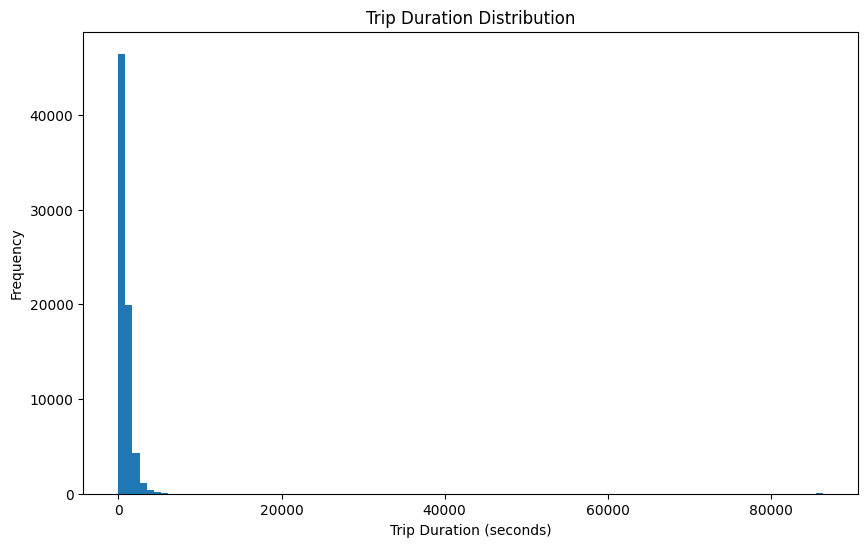

In [32]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

plt.hist(
    duration_sample["trip_duration"],
    bins=100
)

plt.xlabel("Trip Duration (seconds)")
plt.ylabel("Frequency")
plt.title("Trip Duration Distribution")

plt.show()

In [33]:
log_sample = df_train.select(
    "log_trip_duration"
).sample(
    withReplacement=False,
    fraction=0.05,
    seed=42
).limit(100000).toPandas()

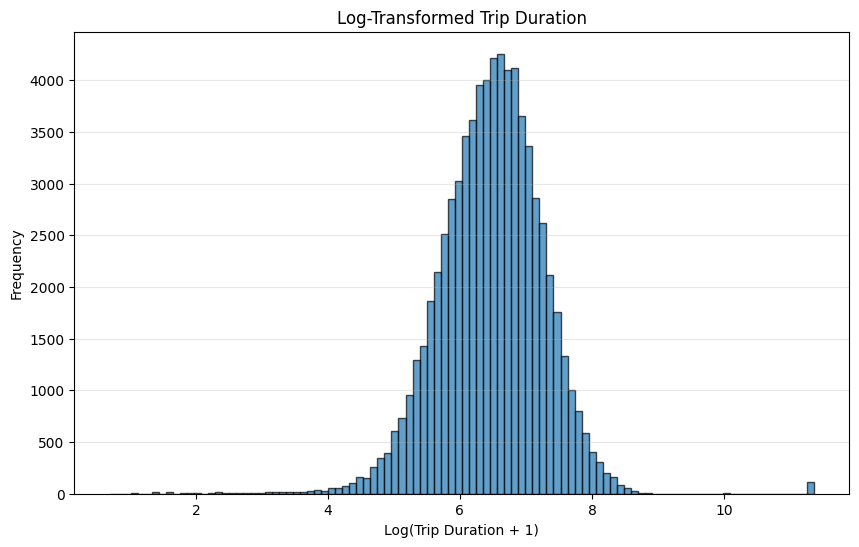

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(log_sample["log_trip_duration"], bins=100, edgecolor="black", alpha=0.7)
plt.xlabel("Log(Trip Duration + 1)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Trip Duration")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [35]:
df_train.groupBy("same_pickup_dropoff").count().show()

+-------------------+-------+
|same_pickup_dropoff|  count|
+-------------------+-------+
|                  0|1451138|
+-------------------+-------+

